# Late Delivery Analysis: What Makes Orders Arrive Late?
**Role:** Data Analyst &nbsp;|&nbsp; **Method:** simple tables, charts and one logistic regression

**Business question:** Which orders are most likely to arrive late, and what should the business do about it?

**Why it matters:** late delivery is the biggest cause of bad reviews in this data (late orders average about 2.6 stars, on-time orders about 4.3).

**Plan**
1. Load the data
2. Look at late rates in simple tables and charts
3. Run one regression to separate the effect of each factor
4. Turn the result into risk groups and recommendations

*Only facts known when the order is placed are used.*

## 1. Load the data

In [8]:
# If you get "ModuleNotFoundError", remove the # on the next line, run it once, then Restart:
# %pip install statsmodels matplotlib pandas pyarrow

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

TEAL, AMBER, RED, GREY = "#348E90", "#D98E1F", "#B84A3E", "#6B6B6B"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 100, "axes.titleweight": "bold"})

# Find the data file. If it is not found, set DATA by hand, e.g.
# DATA = Path("C:/Users/YourName/Desktop/olist_streamlit/data")
print("Notebook is running in:", Path.cwd())

DATA = None
roots = [Path.cwd(), Path.cwd().parent, Path.home() / "Desktop", Path.home() / "Documents",
            Path.home() / "Downloads", Path.home() / "OneDrive"]
for r in roots:
    if r.exists():
        hits = list(r.rglob("ml_late_delivery*.parquet"))
        if hits:
            DATA = hits[0]
            break

if DATA is None:
 raise FileNotFoundError("The file is not on this computer in the usual places. Download it again from the chat.")

print("Using file:", DATA)
df = pd.read_parquet(DATA)
df["month"] = pd.to_datetime(df["purchase_date"]).dt.month
print("Rows:", f"{len(df):,}")
df.head()

df =pd.read_parquet(r"C:\Users\CHARANJEET\Downloads\ml_late_delivery.parquet")
df["month"] = pd.to_datetime(df["purchase_date"]).dt.month
print("Rows:", f"{len(df):,}")
df.head()

Notebook is running in: c:\Users\CHARANJEET\OneDrive\Music\Python_Codes_App
Using file: C:\Users\CHARANJEET\Downloads\ml_late_delivery (1).parquet
Rows: 96,447
Rows: 96,447


,customer_state,seller_state,same_state,state_distance_km,n_items,n_sellers,item_sales,freight,estimated_days,purchase_month,category,purchase_date,is_late,month
0,SP,SP,1,0.0,1.0,1.0,7.79,7.78,14.358333,9,Other,2017-09-26,0.0,9
1,SP,SP,1,0.0,1.0,1.0,45.00,7.78,11.421528,9,telephony,2017-09-15,0.0,9
2,SP,SP,1,0.0,1.0,1.0,30.50,7.78,13.375694,2,toys,2018-02-23,0.0,2
3,SP,SP,1,0.0,1.0,1.0,24.99,7.78,10.947917,11,telephony,2017-11-06,0.0,11
4,SP,SP,1,0.0,1.0,1.0,24.99,7.78,14.012500,11,telephony,2017-11-12,0.0,11


**Columns used**

| Column | Meaning |
|---|---|
| `is_late` | 1 = delivered after the promised date (what we study) |
| `estimated_days` | days promised to the customer |
| `state_distance_km` | distance between the seller's and customer's state centres (rough) |
| `same_state` | 1 if seller and customer are in the same state |
| `n_items`, `item_sales`, `freight` | items, order value (R$), shipping cost (R$) |

## 2. Look at the data

In [9]:
late_rate = df["is_late"].mean()
print(f"Orders: {len(df):,}")
print(f"Late orders: {int(df['is_late'].sum()):,}  ({late_rate:.1%})")
print(f"On-time orders: {int((1 - df['is_late']).sum()):,}  ({1 - late_rate:.1%})")

Orders: 96,447
Late orders: 7,826  (8.1%)
On-time orders: 88,621  (91.9%)


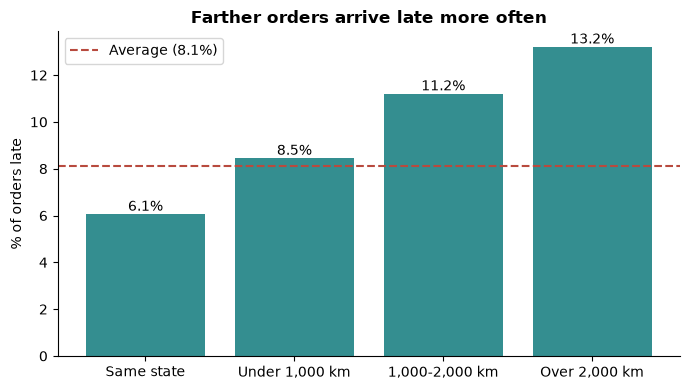

,rate,orders
state_distance_km,,
Same state,6.1%,34686
"Under 1,000 km",8.5%,48037
"1,000-2,000 km",11.2%,7486
"Over 2,000 km",13.2%,6238


In [10]:
# Late rate by distance
b = pd.cut(df["state_distance_km"], [-1, 1, 1000, 2000, 5000],
           labels=["Same state", "Under 1,000 km", "1,000-2,000 km", "Over 2,000 km"])
t = df.groupby(b, observed=True)["is_late"].agg(rate="mean", orders="size")
plt.figure(figsize=(7, 4))
bars = plt.bar(t.index.astype(str), t["rate"] * 100, color=TEAL)
for x, v in zip(bars, t["rate"]):
    plt.text(x.get_x() + x.get_width() / 2, v * 100, f"{v:.1%}", ha="center", va="bottom")
plt.axhline(late_rate * 100, color=RED, ls="--", label=f"Average ({late_rate:.1%})")
plt.title("Farther orders arrive late more often"); plt.ylabel("% of orders late"); plt.legend()
plt.tight_layout(); plt.show()
t.assign(rate=t["rate"].map("{:.1%}".format))

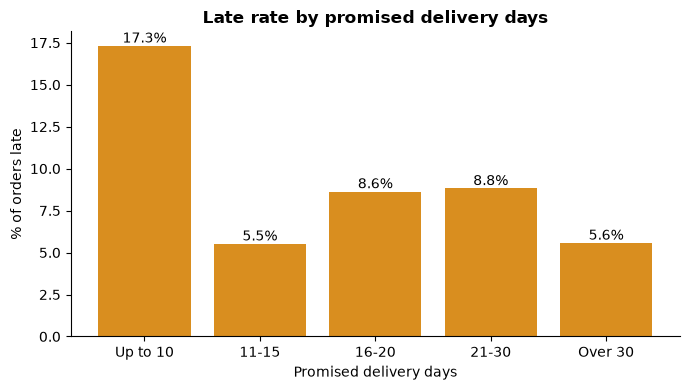

,rate,orders
estimated_days,,
Up to 10,17.3%,3945
11-15,5.5%,10092
16-20,8.6%,16621
21-30,8.8%,45924
Over 30,5.6%,19630


In [11]:
# Late rate by promised delivery days
b = pd.cut(df["estimated_days"], [0, 10, 15, 20, 30, 60], labels=["Up to 10", "11-15", "16-20", "21-30", "Over 30"])
t = df.groupby(b, observed=True)["is_late"].agg(rate="mean", orders="size")
plt.figure(figsize=(7, 4))
bars = plt.bar(t.index.astype(str), t["rate"] * 100, color=AMBER)
for x, v in zip(bars, t["rate"]):
    plt.text(x.get_x() + x.get_width() / 2, v * 100, f"{v:.1%}", ha="center", va="bottom")
plt.title("Late rate by promised delivery days"); plt.xlabel("Promised delivery days"); plt.ylabel("% of orders late")
plt.tight_layout(); plt.show()
t.assign(rate=t["rate"].map("{:.1%}".format))

**Careful with this chart:** it does not fall in a straight line. Far-away orders get longer promises, so distance and promise are mixed together here. Section 3 separates them.

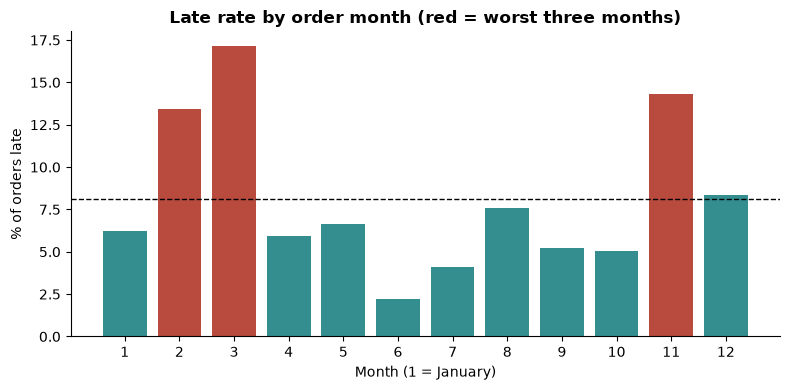

Worst months: month 3: 17.2%, month 11: 14.3%, month 2: 13.4%


In [12]:
# Late rate by order month
t = df.groupby("month")["is_late"].mean() * 100
plt.figure(figsize=(8, 4))
plt.bar(t.index.astype(str), t.values, color=[RED if m in (2, 3, 11) else TEAL for m in t.index])
plt.axhline(late_rate * 100, color="black", ls="--", lw=1)
plt.title("Late rate by order month (red = worst three months)")
plt.xlabel("Month (1 = January)"); plt.ylabel("% of orders late")
plt.tight_layout(); plt.show()
print("Worst months:", ", ".join(f"month {m}: {v:.1f}%" for m, v in t.sort_values(ascending=False).head(3).items()))

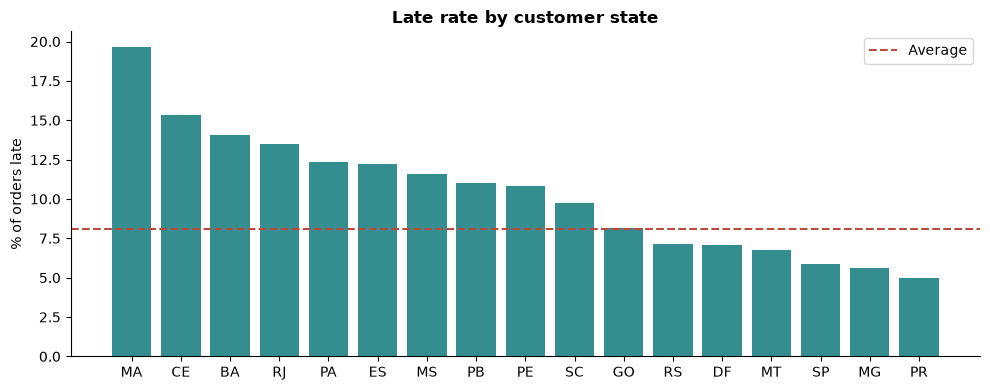

In [13]:
# Late rate by customer state (states with at least 500 orders)
df["customer_state"] = df["customer_state"].astype(str)
g = df.groupby("customer_state")["is_late"].agg(rate="mean", orders="size")
g = g[g["orders"] >= 500].sort_values("rate", ascending=False)
plt.figure(figsize=(10, 4))
plt.bar(g.index, g["rate"] * 100, color=TEAL)
plt.axhline(late_rate * 100, color=RED, ls="--", label="Average")
plt.title("Late rate by customer state"); plt.ylabel("% of orders late"); plt.legend()
plt.tight_layout(); plt.show()

### Distance and promise together
Distance and promised days both matter. This table shows them side by side.
Cells with fewer than 100 orders are greyed out, because a rate based on a handful of orders is not reliable.

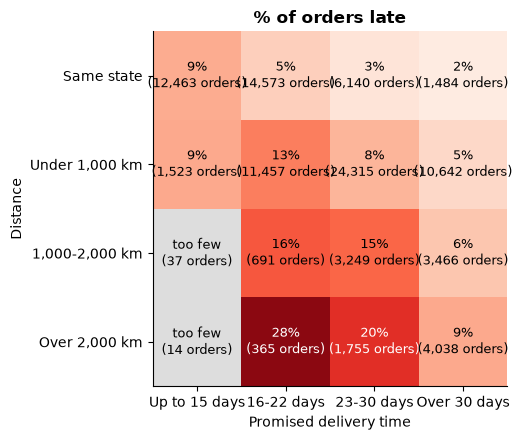

In [14]:
d = pd.cut(df["state_distance_km"], [-1, 1, 1000, 2000, 5000],
           labels=["Same state", "Under 1,000 km", "1,000-2,000 km", "Over 2,000 km"])
e = pd.cut(df["estimated_days"], [0, 15, 22, 30, 60], labels=["Up to 15 days", "16-22 days", "23-30 days", "Over 30 days"])
rate = df.pivot_table(index=d, columns=e, values="is_late", aggfunc="mean", observed=True)
cnt = df.pivot_table(index=d, columns=e, values="is_late", aggfunc="size", observed=True)
shown = rate.where(cnt >= 100)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.imshow(np.ma.masked_invalid(shown.values), cmap="Reds", vmin=0, vmax=0.3)
ax.set_facecolor("#DDDDDD")
for i in range(shown.shape[0]):
    for j in range(shown.shape[1]):
        v, n = shown.values[i, j], cnt.values[i, j]
        ax.text(j, i, f"{v:.0%}\n({n:,} orders)" if not np.isnan(v) else f"too few\n({n:,} orders)",
                ha="center", va="center", fontsize=9, color="black" if np.isnan(v) or v < 0.2 else "white")
ax.set_xticks(range(shown.shape[1])); ax.set_xticklabels(shown.columns)
ax.set_yticks(range(shown.shape[0])); ax.set_yticklabels(shown.index)
ax.set_xlabel("Promised delivery time"); ax.set_ylabel("Distance")
ax.set_title("% of orders late")
plt.tight_layout(); plt.show()

**What the table shows**
- Late rates rise with distance. Within each distance row, orders with the longest promises are mostly the safest.
- The worst large group is orders travelling over 2,000 km with a 16-22 day promise.
- Very short promises over long distances are rare in this data, so we cannot measure them well.

## 3. Regression: the effect of each factor on its own

The tables above mix factors together. For example, far orders also tend to have longer promises. A **logistic regression** separates them, so we can say how much each factor matters **with the others held equal**.

How to read the result: an **odds ratio** above 1 raises the chance of a late order, below 1 lowers it. A **p-value** under 0.05 means the effect is unlikely to be random.

In [15]:
# Put the factors in easy-to-read units
df["dist_1000km"] = df["state_distance_km"] / 1000          # per 1,000 km
df["value_100"] = df["item_sales"] / 100                    # per R$100
df["freight_10"] = df["freight"] / 10                       # per R$10
df["peak_month"] = df["month"].isin([2, 3, 11]).astype(int) # the 3 worst months seen above

factors = ["dist_1000km", "same_state", "estimated_days", "n_items", "value_100", "freight_10", "peak_month"]
X = sm.add_constant(df[factors].astype(float))
y = df["is_late"].astype(float)
model = sm.Logit(y, X).fit(disp=0)

ci = np.exp(model.conf_int())
result = pd.DataFrame({"odds_ratio": np.exp(model.params), "ci_low": ci[0], "ci_high": ci[1],
                       "p_value": model.pvalues}).drop("const")
result.round(3)

,odds_ratio,ci_low,ci_high,p_value
dist_1000km,1.810,1.727,1.897,0.000
same_state,0.490,0.456,0.526,0.000
estimated_days,0.916,0.912,0.920,0.000
n_items,0.832,0.785,0.882,0.000
value_100,1.017,1.007,1.028,0.001
freight_10,1.029,1.017,1.042,0.000
peak_month,3.123,2.976,3.276,0.000


In [16]:
names = {"dist_1000km": "Each extra 1,000 km", "same_state": "Seller and customer in same state",
         "estimated_days": "Each extra promised day", "n_items": "Each extra item in the order",
         "value_100": "Each extra R$100 of order value", "freight_10": "Each extra R$10 of freight",
         "peak_month": "Order placed in Feb, Mar or Nov"}
print("In plain English (everything else held equal):\n")
for k, r in result.sort_values("odds_ratio", ascending=False).iterrows():
    change = (r["odds_ratio"] - 1) * 100
    word = "raises" if change > 0 else "cuts"
    sig = "" if r["p_value"] < 0.05 else "   (not statistically clear)"
    print(f"- {names[k]}: {word} the odds of a late order by {abs(change):.0f}%{sig}")

In plain English (everything else held equal):

- Order placed in Feb, Mar or Nov: raises the odds of a late order by 212%
- Each extra 1,000 km: raises the odds of a late order by 81%
- Each extra R$10 of freight: raises the odds of a late order by 3%
- Each extra R$100 of order value: raises the odds of a late order by 2%
- Each extra promised day: cuts the odds of a late order by 8%
- Each extra item in the order: cuts the odds of a late order by 17%
- Seller and customer in same state: cuts the odds of a late order by 51%


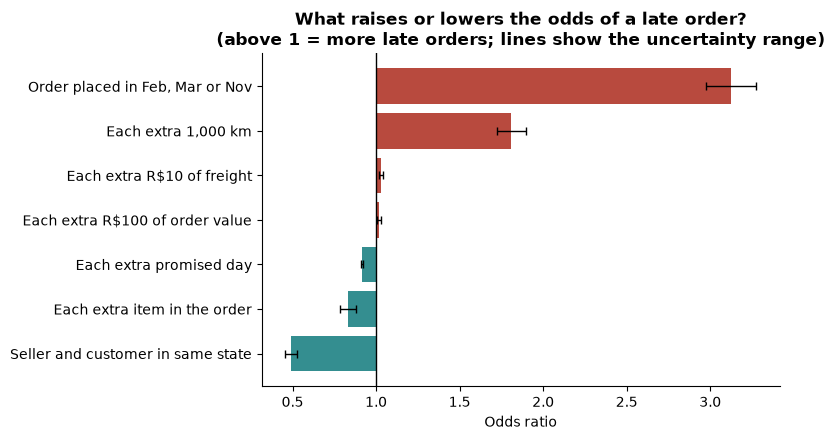

In [17]:
# Chart of the odds ratios with their uncertainty range
r = result.sort_values("odds_ratio")
plt.figure(figsize=(8, 4.5))
plt.barh([names[i] for i in r.index], r["odds_ratio"] - 1, left=1,
         color=[RED if v > 1 else TEAL for v in r["odds_ratio"]])
plt.errorbar(r["odds_ratio"], range(len(r)), xerr=[r["odds_ratio"] - r["ci_low"], r["ci_high"] - r["odds_ratio"]],
             fmt="none", ecolor="black", capsize=3, lw=1)
plt.axvline(1, color="black", lw=1)
plt.title("What raises or lowers the odds of a late order?\n(above 1 = more late orders; lines show the uncertainty range)")
plt.xlabel("Odds ratio")
plt.tight_layout(); plt.show()

**What the regression shows**
- **Peak months** (Feb, Mar, Nov) are the biggest factor. These months had delivery problems that are not explained by anything else in the data.
- **Distance** raises the odds of a late order. **A longer promise** lowers them. Both are clear effects.
- **Same state** orders are much less likely to be late.
- Order value and freight have small effects. Do not build a story on them.
- More items in the order slightly lowers the odds, which is surprising. Treat it with care.

**Honest note:** the model explains only part of why orders are late (pseudo R-squared is below 0.1). Weather, strikes, carrier and seller delays are not in the data.

In [18]:
print(f"Pseudo R-squared: {model.prsquared:.3f}   (how much of the pattern the model explains; low is normal for this kind of question)")
print(f"Orders used: {int(model.nobs):,}")

Pseudo R-squared: 0.079   (how much of the pattern the model explains; low is normal for this kind of question)
Orders used: 96,447


## 4. Risk groups: turn the model into something the business can use

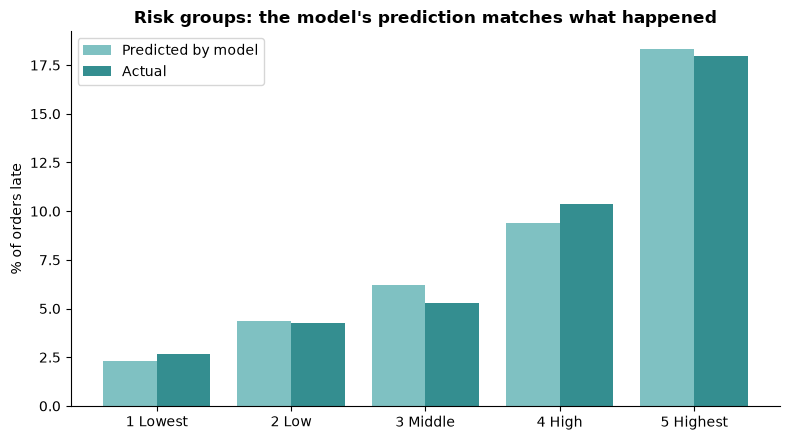

The highest-risk 20% of orders are late 18.0% of the time.
The lowest-risk 20% are late 2.7% of the time. That is 7 times less.
The highest-risk group is 2.2x the average (8.1%).


,orders,predicted_late,actual_late
group,,,
1 Lowest,19290,2.3%,2.7%
2 Low,19289,4.3%,4.2%
3 Middle,19289,6.2%,5.3%
4 High,19289,9.4%,10.4%
5 Highest,19290,18.3%,18.0%


In [19]:
# Score every order, then sort into 5 equal groups from lowest to highest risk
df["risk"] = model.predict(X)
df["group"] = pd.qcut(df["risk"].rank(method="first"), 5,
                      labels=["1 Lowest", "2 Low", "3 Middle", "4 High", "5 Highest"])
g = df.groupby("group", observed=True).agg(orders=("is_late", "size"),
                                           predicted_late=("risk", "mean"),
                                           actual_late=("is_late", "mean"))

x = np.arange(len(g))
plt.figure(figsize=(8, 4.5))
plt.bar(x - 0.2, g["predicted_late"] * 100, 0.4, color="#7FC1C2", label="Predicted by model")
plt.bar(x + 0.2, g["actual_late"] * 100, 0.4, color=TEAL, label="Actual")
plt.xticks(x, g.index)
plt.title("Risk groups: the model's prediction matches what happened")
plt.ylabel("% of orders late"); plt.legend()
plt.tight_layout(); plt.show()

hi, lo = g.loc["5 Highest", "actual_late"], g.loc["1 Lowest", "actual_late"]
print(f"The highest-risk 20% of orders are late {hi:.1%} of the time.")
print(f"The lowest-risk 20% are late {lo:.1%} of the time. That is {hi / lo:.0f} times less.")
print(f"The highest-risk group is {hi / late_rate:.1f}x the average ({late_rate:.1%}).")
g.assign(predicted_late=g["predicted_late"].map("{:.1%}".format), actual_late=g["actual_late"].map("{:.1%}".format))

**Note:** this model was fitted on all the data, so it describes the past. It was not tested on new orders. That is normal for an explanatory analysis, but it means we do not claim it will forecast perfectly.

### What-if calculator
Change the numbers to see how the late-delivery chance moves for an order.

In [20]:
def late_chance(distance_km, promised_days, items=1, value=120, freight=20, peak_month=False):
    """Estimated chance (%) that an order is late."""
    row = pd.DataFrame([{"const": 1.0, "dist_1000km": distance_km / 1000, "same_state": float(distance_km == 0),
                         "estimated_days": promised_days, "n_items": items, "value_100": value / 100,
                         "freight_10": freight / 10, "peak_month": float(peak_month)}])
    return float(model.predict(row[X.columns])[0]) * 100

examples = [
    ("Same state, 15 days promised, normal month", dict(distance_km=0, promised_days=15)),
    ("Same state, 15 days promised, peak month",   dict(distance_km=0, promised_days=15, peak_month=True)),
    ("1,500 km, 20 days promised, normal month",   dict(distance_km=1500, promised_days=20)),
    ("1,500 km, 20 days promised, peak month",     dict(distance_km=1500, promised_days=20, peak_month=True)),
    ("1,500 km, 30 days promised, normal month",   dict(distance_km=1500, promised_days=30)),
    ("2,500 km, 20 days promised, normal month",   dict(distance_km=2500, promised_days=20)),
    ("2,500 km, 20 days promised, peak month",     dict(distance_km=2500, promised_days=20, peak_month=True)),
]
pd.DataFrame({"Order": [e[0] for e in examples],
              "Chance of being late": [f"{late_chance(**e[1]):.1f}%" for e in examples]})

,Order,Chance of being late
0,"Same state, 15 days promised, normal month",4.8%
1,"Same state, 15 days promised, peak month",13.6%
2,"1,500 km, 20 days promised, normal month",13.9%
3,"1,500 km, 20 days promised, peak month",33.5%
4,"1,500 km, 30 days promised, normal month",6.3%
5,"2,500 km, 20 days promised, normal month",22.6%
6,"2,500 km, 20 days promised, peak month",47.7%


**Careful:** only use the calculator for realistic orders. Very long distances with very short promises hardly exist in this data, so the answer there is a guess, not a measurement.

## 5. Findings and recommendations

**Findings**
1. About 1 in 12 orders (8.1%) arrives late.
2. Late rates rise with distance. With distance and month held equal, a longer promised delivery time lowers the risk.
3. Three months (Feb, Mar, Nov) are far worse than the rest. They roughly triple the odds of a late order.
4. Orders within the same state are the safest.
5. The highest-risk 20% of orders are late about 6 to 7 times as often as the lowest-risk 20%.

**Recommendations**
1. **Promise more days on long-distance orders.** Orders over 2,000 km with a 16-22 day promise (365 orders) are late about 28% of the time. A longer, honest promise cuts late orders.
2. **Prepare for peak months.** Add carrier capacity and warn customers before Feb, Mar and Nov.
3. **Flag the highest-risk 20% of orders** at checkout, so they can be shipped first or get a safer promise.
4. **Keep an eye on the weakest states** (see the state chart) and talk to the carriers serving them.

**Limits**
- Weather, strikes, carrier and seller delays are not in the data.
- Distance is measured between state centres, so it is rough.
- Peak months may reflect one-off events, so they may not repeat.
- Results show links in past data, not proof of cause.

**Next step:** add zip-code distance and each seller's past late rate.